# Regression using Deep Neural Networks

## Load Dataset from sklearn

In [4]:
#!pip install scikit-learn

In [5]:
import pandas as pd # 라이브러리 임포트
import seaborn as sns # 라이브러리 임포트
import matplotlib.pyplot as plt # 라이브러리 임포트

from sklearn.preprocessing import StandardScaler # 라이브러리 임포트

In [6]:
#from sklearn.datasets import load_boston
from sklearn.datasets import fetch_openml # 라이브러리 임포트
import numpy as np # 라이브러리 임포트

_raw = fetch_openml(name='boston', version=1, as_frame=False) # 데이터셋 로드

class _BostonProxy: # 클래스 정의
    def __init__(self, d): # 함수 정의
        self.data = d.data.astype(float)   # 변수 설정
        self.target = d.target.astype(float) # 변수 설정
        self.feature_names = d.feature_names # 변수 설정

boston = _BostonProxy(_raw) # 변수 설정

In [7]:
df = pd.DataFrame(boston.data, columns=boston.feature_names) # 데이터프레임 생성
df["TARGET"] = boston.target # 변수 설정
df.tail() # 코드 실행

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,TARGET
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1.0,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1.0,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1.0,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1.0,273.0,21.0,393.45,6.48,22.0
505,0.04741,0.0,11.93,0.0,0.573,6.030,80.8,2.5050,1.0,273.0,21.0,396.90,7.88,11.9


In [8]:
scaler = StandardScaler() # 변수 설정
scaler.fit(df.values[:, :-1]) # 코드 실행
df.values[:, :-1] = scaler.transform(df.values[:, :-1]).round(4) # 변수 설정

df.tail() # 코드 실행

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,TARGET
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1.0,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1.0,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1.0,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1.0,273.0,21.0,393.45,6.48,22.0
505,0.04741,0.0,11.93,0.0,0.573,6.030,80.8,2.5050,1.0,273.0,21.0,396.90,7.88,11.9


## Train Model with PyTorch

In [9]:
import torch # 라이브러리 임포트
import torch.nn as nn # 라이브러리 임포트
import torch.nn.functional as F # 라이브러리 임포트
import torch.optim as optim # 라이브러리 임포트

In [10]:
data = torch.from_numpy(df.values).float() # 텐서 변환

data.shape # 코드 실행

torch.Size([506, 14])

In [11]:
y = data[:, -1:] # 변수 설정
x = data[:, :-1] # 변수 설정

print(x.shape, y.shape) # 결과 출력

torch.Size([506, 13]) torch.Size([506, 1])


In [12]:
n_epochs = 100000 # 에포크 설정
learning_rate = 1e-4 # 학습률 설정
print_interval = 5000 # 변수 설정

## Build Models

### Build Model using nn.Module

In [13]:
relu = nn.ReLU() # ReLU 활성화 함수
leaky_relu = nn.LeakyReLU(0.1) # ReLU 활성화 함수

In [14]:
class MyModel(nn.Module): # 클래스 정의
    
    def __init__(self, input_dim, output_dim): # 함수 정의
        self.input_dim = input_dim # 변수 설정
        self.output_dim = output_dim # 변수 설정
        
        super().__init__() # 코드 실행
        
        self.linear1 = nn.Linear(input_dim, 3) # 선형층 정의
        self.linear2 = nn.Linear(3, 3) # 선형층 정의
        self.linear3 = nn.Linear(3, 3) # 선형층 정의
        self.linear4 = nn.Linear(3, output_dim) # 선형층 정의
        self.act = nn.ReLU() # ReLU 활성화 함수
        
    def forward(self, x): # 함수 정의
        # |x| = (batch_size, input_dim)
        h = self.act(self.linear1(x)) # 변수 설정
        h = self.act(self.linear2(h)) # 변수 설정
        h = self.act(self.linear3(h)) # 변수 설정
        y = self.linear4(h) # 변수 설정
        # |y| = (batch_size, output_dim)
        
        return y # 결과 반환
    
model = MyModel(x.size(-1), y.size(-1)) # 변수 설정

model # 코드 실행

MyModel(
  (linear1): Linear(in_features=13, out_features=3, bias=True)
  (linear2): Linear(in_features=3, out_features=3, bias=True)
  (linear3): Linear(in_features=3, out_features=3, bias=True)
  (linear4): Linear(in_features=3, out_features=1, bias=True)
  (act): ReLU()
)

In [15]:
optimizer = optim.SGD(model.parameters(), # 최적화 알고리즘 설정
                      lr=learning_rate) # 학습률 설정

In [16]:
for i in range(n_epochs): # 반복문 수행
    y_hat = model(x) # 모델 예측
    loss = F.mse_loss(y_hat, y) # 손실 함수 정의
    
    optimizer.zero_grad() # 기울기 초기화
    loss.backward() # 역전파 수행
    
    optimizer.step() # 가중치 업데이트
    
    if (i + 1) % print_interval == 0: # 조건문 수행
        print('Epoch %d: loss=%.4e' % (i + 1, loss)) # 결과 출력

C:\Users\dg823\AppData\Local\Temp\ipykernel_1624\3844287985.py:11: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  print('Epoch %d: loss=%.4e' % (i + 1, loss))


Epoch 5000: loss=5.8723e+01
Epoch 10000: loss=4.7849e+01
Epoch 15000: loss=4.5166e+01
Epoch 20000: loss=4.3162e+01
Epoch 25000: loss=3.4575e+01
Epoch 30000: loss=4.4650e+01
Epoch 35000: loss=3.1196e+01
Epoch 40000: loss=3.1333e+01
Epoch 45000: loss=3.1552e+01
Epoch 50000: loss=3.2394e+01
Epoch 55000: loss=3.0484e+01
Epoch 60000: loss=3.1039e+01
Epoch 65000: loss=3.0037e+01
Epoch 70000: loss=2.8502e+01
Epoch 75000: loss=2.5141e+01
Epoch 80000: loss=2.2698e+01
Epoch 85000: loss=2.2227e+01
Epoch 90000: loss=2.7227e+01
Epoch 95000: loss=2.3180e+01
Epoch 100000: loss=2.4402e+01


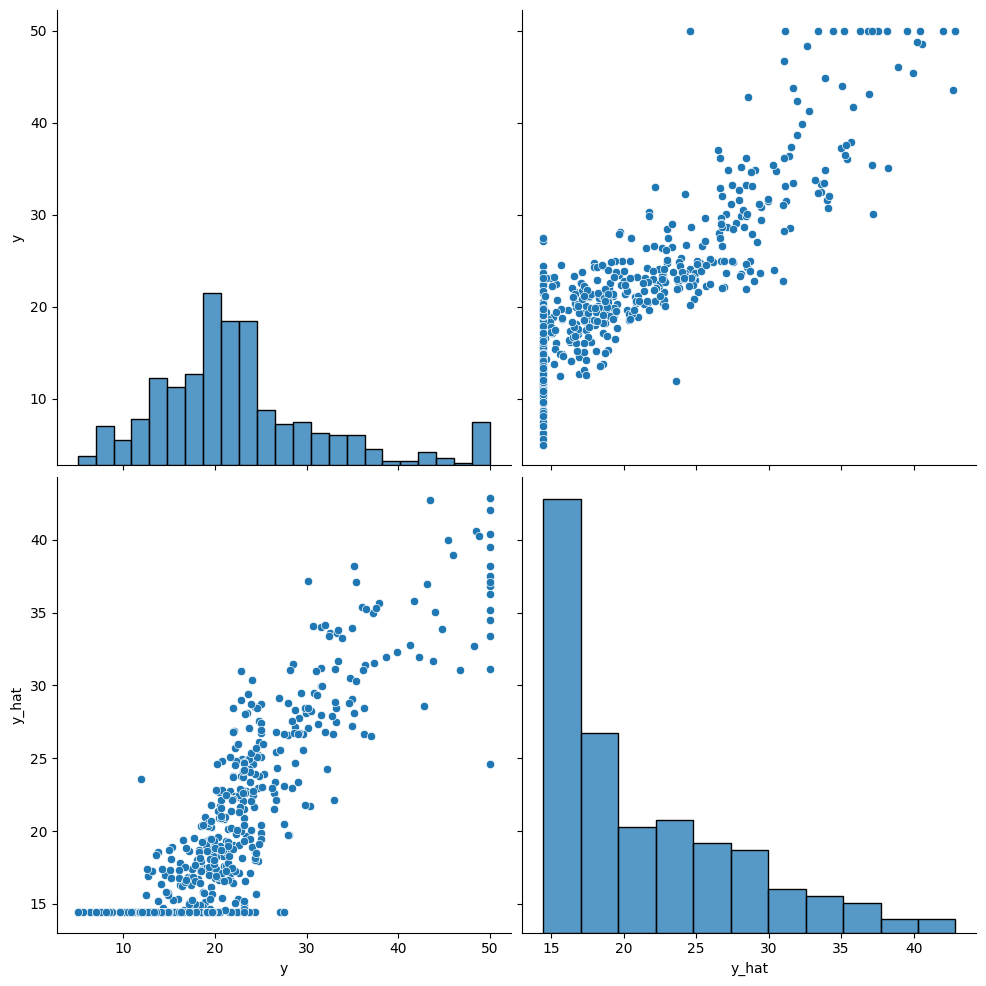

In [17]:
df = pd.DataFrame(torch.cat([y, y_hat], dim=1).detach().numpy(), # 데이터프레임 생성
                  columns=["y", "y_hat"]) # 변수 설정

sns.pairplot(df, height=5) # 변수 설정
plt.show() # 그래프 출력

### Build Model with LeakyReLU using nn.Sequential

In [18]:
model1 = nn.Sequential( # 변수 설정
    nn.Linear(x.size(-1), 3), # 선형층 정의
    nn.LeakyReLU(), # ReLU 활성화 함수
    nn.Linear(3, 3), # 선형층 정의
    nn.LeakyReLU(), # ReLU 활성화 함수
    nn.Linear(3, 3), # 선형층 정의
    nn.LeakyReLU(), # ReLU 활성화 함수
    nn.Linear(3, 3), # 선형층 정의
    nn.LeakyReLU(), # ReLU 활성화 함수
    nn.Linear(3, y.size(-1)), # 선형층 정의
) # 코드 실행

model1 # 코드 실행

Sequential(
  (0): Linear(in_features=13, out_features=3, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=3, out_features=3, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=3, out_features=3, bias=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=3, out_features=3, bias=True)
  (7): LeakyReLU(negative_slope=0.01)
  (8): Linear(in_features=3, out_features=1, bias=True)
)

In [19]:
optimizer = optim.SGD(model1.parameters(), # 최적화 알고리즘 설정
                      lr=learning_rate) # 학습률 설정

In [20]:
for i in range(n_epochs): # 반복문 수행
    y_hat = model1(x) # 모델 예측
    loss = F.mse_loss(y_hat, y) # 손실 함수 정의
    
    optimizer.zero_grad() # 기울기 초기화
    loss.backward() # 역전파 수행
    
    optimizer.step() # 가중치 업데이트
    
    if (i + 1) % print_interval == 0: # 조건문 수행
        print('Epoch %d: loss=%.4e' % (i + 1, loss)) # 결과 출력

Epoch 5000: loss=6.6780e+01
Epoch 10000: loss=5.7439e+01
Epoch 15000: loss=4.9622e+01
Epoch 20000: loss=4.3944e+01
Epoch 25000: loss=4.1577e+01
Epoch 30000: loss=3.9881e+01
Epoch 35000: loss=3.8582e+01
Epoch 40000: loss=3.6308e+01
Epoch 45000: loss=2.8401e+01
Epoch 50000: loss=2.2029e+01
Epoch 55000: loss=1.6541e+01
Epoch 60000: loss=1.7816e+01
Epoch 65000: loss=1.7976e+01
Epoch 70000: loss=1.7712e+01
Epoch 75000: loss=1.7724e+01
Epoch 80000: loss=2.0641e+01
Epoch 85000: loss=1.9637e+01
Epoch 90000: loss=1.6462e+01
Epoch 95000: loss=1.5367e+01
Epoch 100000: loss=1.5326e+01


## Let's see the result!

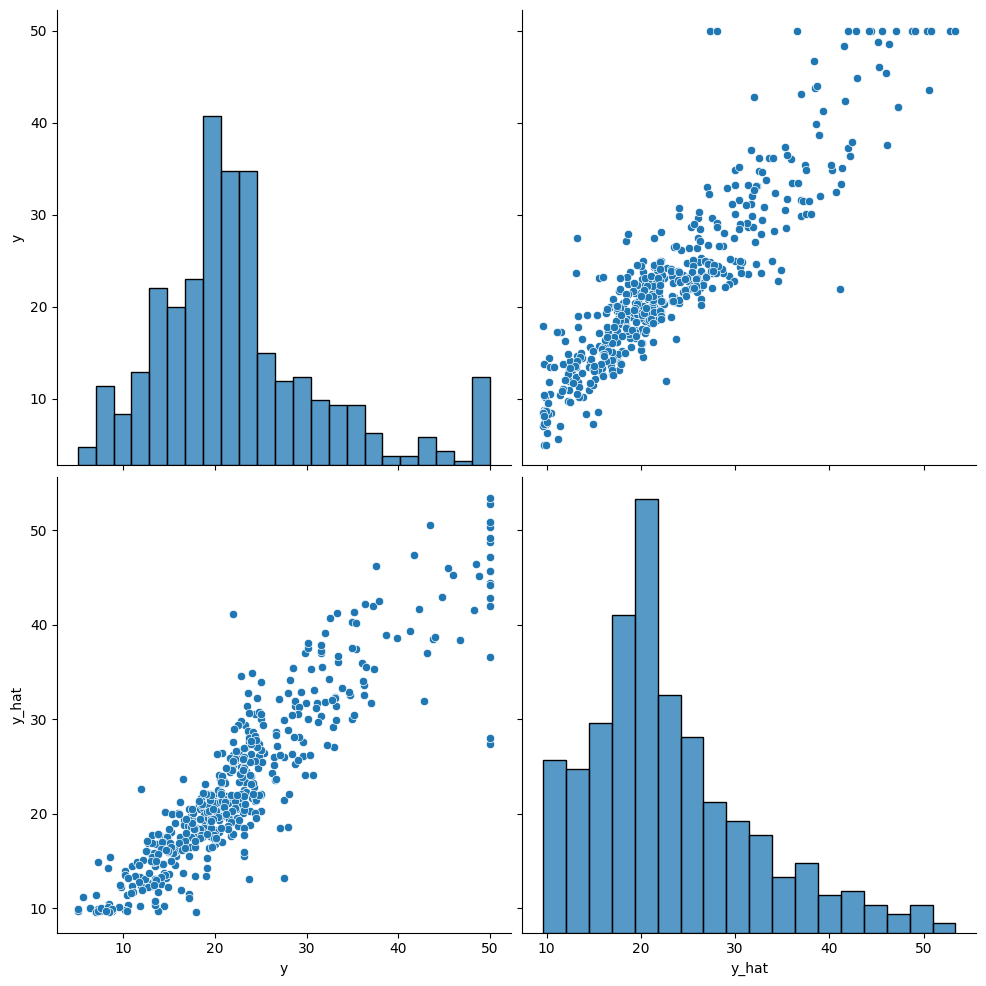

In [21]:
df = pd.DataFrame(torch.cat([y, y_hat], dim=1).detach().numpy(), # 데이터프레임 생성
                  columns=["y", "y_hat"]) # 변수 설정

sns.pairplot(df, height=5) # 변수 설정
plt.show() # 그래프 출력